<a href="https://colab.research.google.com/github/aaronawsg/capstone/blob/main/Capstone_Economics_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone

In [22]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# ---- Chart style: light surface, recessive grid, text in ink (never in series colors)
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE = "#2a78d6"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.family": "sans-serif", "font.size": 10,
    "figure.dpi": 110,
})

# ---- One color per country, assigned in a fixed order (color follows the entity)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
COUNTRIES = ["Australia", "Canada", "China", "India", "Russia", "USA"]
COUNTRY_COLOR = dict(zip(COUNTRIES, SERIES))

# Diverging scale for correlations: blue <-> neutral gray <-> red
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")

In [23]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

# CSV import
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Global Economic Data.csv')  # 'data.csv' is the CSV file


df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Country,Year,GDP (in Trillions USD),GDP per Capita (in USD),Inflation Rate (%),Population (in Millions),Population Growth Rate (%),Urban Population (%),Life Expectancy (Years),Healthcare Expenditure per Capita (USD),Doctor-to-Patient Ratio,Literacy Rate (%),Education Expenditure as % of GDP,Internet Penetration (%),Smartphone Adoption (%),Energy Consumption (TWh),Renewable Energy Share (%),Military Expenditure (in Billion USD),Number of Active Military Personnel,CO2 Emissions (Million Metric Tons),Forest Coverage (%),Number of Airports,Road Network Length (in km),Public Transport Usage (%),Human Development Index (HDI),Gender Equality Index,Poverty Rate (%),Number of International Visitors (in Millions),Tourism Revenue (in Billion USD),Agricultural Land (%),Unemployment Rate (%),Labor Force Participation Rate (%),"Crime Rate (per 100,000)",Corruption Perception Index,Freedom of Press Index,Voting Participation Rate (%)
0,USA,2000,20.87,65455.0,2.28,330.34,0.58,83.42,78.39,11209.00,2.60,100.78,5.12,84.73,88.23,4095.0,17.31,724.68,1464400.0,5156.10,31.88,13869.00,6626400.0,11.74,0.97,0.94,10.98,80.80,210.98,42.37,3.55,65.52,287.40,67.41,45.27,68.81
1,Russia,2000,1.64,10923.0,3.25,141.81,0.10,72.67,69.91,534.45,4.05,103.55,4.37,84.84,72.88,1058.4,18.60,62.13,986000.0,1660.80,49.15,1251.60,1429500.0,24.00,0.85,0.72,12.89,24.70,36.47,12.53,4.63,57.54,497.50,30.90,146.10,65.00
2,Canada,2000,1.65,47932.0,1.96,36.63,0.90,79.54,84.60,5113.50,2.84,98.31,5.69,89.75,85.99,559.9,68.81,22.58,67972.5,516.78,36.18,501.50,985000.0,17.51,0.96,0.94,9.46,22.33,29.52,7.22,5.43,65.06,795.20,74.74,16.42,63.00
3,China,2000,13.64,10060.0,2.43,1446.93,0.31,58.56,76.09,459.00,1.86,98.65,4.02,66.56,71.12,6698.0,28.94,255.52,2045900.0,9690.00,22.00,230.16,4995000.0,35.50,0.72,0.85,2.04,62.20,115.80,54.00,3.68,63.13,102.90,41.75,185.32,72.14
4,India,2000,2.98,2102.1,4.87,1313.76,1.04,34.09,68.78,76.07,0.86,73.11,3.19,46.40,41.98,1500.0,11.50,70.01,1475768.0,2443.20,24.48,258.50,5929500.0,23.09,0.67,0.66,22.25,11.25,29.12,57.60,7.31,52.10,245.25,40.12,136.36,67.65


In [24]:
df.info()
print("\nShape (rows, columns):", df.shape)

print("Full duplicate rows:", int(df.duplicated().sum()))
print("Missing cells:", int(df.isna().sum().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 36 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Country                                         144 non-null    object 
 1   Year                                            144 non-null    int64  
 2   GDP (in Trillions USD)                          144 non-null    float64
 3   GDP per Capita (in USD)                         144 non-null    float64
 4   Inflation Rate (%)                              144 non-null    float64
 5   Population (in Millions)                        144 non-null    float64
 6   Population Growth Rate (%)                      144 non-null    float64
 7   Urban Population (%)                            144 non-null    float64
 8   Life Expectancy (Years)                         144 non-null    float64
 9   Healthcare Expenditure per Capita (USD)    

In [25]:
df.isnull().sum()

,0
Country,0
Year,0
GDP (in Trillions USD),0
GDP per Capita (in USD),0
Inflation Rate (%),0
Population (in Millions),0
Population Growth Rate (%),0
Urban Population (%),0
Life Expectancy (Years),0
Healthcare Expenditure per Capita (USD),0


In [26]:
df.isna().sum()

,0
Country,0
Year,0
GDP (in Trillions USD),0
GDP per Capita (in USD),0
Inflation Rate (%),0
Population (in Millions),0
Population Growth Rate (%),0
Urban Population (%),0
Life Expectancy (Years),0
Healthcare Expenditure per Capita (USD),0


In [27]:

# To drop rows where there are blank cells
df.dropna(inplace=True)



In [28]:
# verify all null is removed
df.isna().sum()

,0
Country,0
Year,0
GDP (in Trillions USD),0
GDP per Capita (in USD),0
Inflation Rate (%),0
Population (in Millions),0
Population Growth Rate (%),0
Urban Population (%),0
Life Expectancy (Years),0
Healthcare Expenditure per Capita (USD),0


In [29]:
df.shape

(144, 36)

### 1.1 Range and consistency checks

Percentages should sit between 0 and 100, and the HDI and Gender Equality Index between 0 and 1.

In [30]:
checks = []

for c in [c for c in df.columns if "(%)" in c]:
    bad = ((df[c] < 0) | (df[c] > 100)).sum()
    checks.append((c, "between 0 and 100", int(bad), df[c].min(), df[c].max()))

for c in ["Human Development Index (HDI)", "Gender Equality Index"]:
    bad = ((df[c] < 0) | (df[c] > 1)).sum()
    checks.append((c, "between 0 and 1", int(bad), df[c].min(), df[c].max()))

range_report = pd.DataFrame(checks, columns=["Column", "Rule", "Violations", "Min", "Max"])
print(f"{len(range_report)} columns checked, {int((range_report.Violations > 0).sum())} with violations")
range_report[range_report["Violations"] > 0]

16 columns checked, 2 with violations


,Column,Rule,Violations,Min,Max
3,Literacy Rate (%),between 0 and 100,42,70.60,103.95
15,Gender Equality Index,between 0 and 1,6,0.63,1.03


In [31]:
# Cap Literacy Rate (%) at 100 and Gender Equality Index at 1
df["Literacy Rate (%)"] = df["Literacy Rate (%)"].clip(upper=100)
df["Gender Equality Index"] = df["Gender Equality Index"].clip(upper=1)

In [32]:
checks = []

for c in [c for c in df.columns if "(%)" in c]:
    bad = ((df[c] < 0) | (df[c] > 100)).sum()
    checks.append((c, "between 0 and 100", int(bad), df[c].min(), df[c].max()))

for c in ["Human Development Index (HDI)", "Gender Equality Index"]:
    bad = ((df[c] < 0) | (df[c] > 1)).sum()
    checks.append((c, "between 0 and 1", int(bad), df[c].min(), df[c].max()))

range_report = pd.DataFrame(checks, columns=["Column", "Rule", "Violations", "Min", "Max"])
print(f"{len(range_report)} columns checked, {int((range_report.Violations > 0).sum())} with violations")
range_report[range_report["Violations"] > 0]

16 columns checked, 0 with violations


,Column,Rule,Violations,Min,Max


In [33]:
OUTPUT_CSV = "Global_Economic_Data_Cleaned.csv"

n_rows = len(df)
df = df.sort_values(["Country", "Year"]).reset_index(drop=True)

# Flag first, then cap at the theoretical maximum (nothing is hidden).
# The guard makes this cell safe to re-run without wiping the flags.
if "Literacy Rate Capped Flag" not in df.columns:
    df["Literacy Rate Capped Flag"] = (df["Literacy Rate (%)"] > 100).astype(int)
    df["Gender Equality Capped Flag"] = (df["Gender Equality Index"] > 1).astype(int)
df["Literacy Rate (%)"] = df["Literacy Rate (%)"].clip(upper=100)
df["Gender Equality Index"] = df["Gender Equality Index"].clip(upper=1)

# Reference column for the GDP per Capita consistency check
df["GDPpc Implied (USD)"] = (df["GDP (in Trillions USD)"] * 1e6 / df["Population (in Millions)"]).round(1)

# Verify
assert len(df) == n_rows
assert df["Literacy Rate (%)"].max() <= 100
assert df["Gender Equality Index"].max() <= 1
assert df.isna().sum().sum() == 0

print("Literacy values capped:", int(df["Literacy Rate Capped Flag"].sum()))
print("Gender Equality values capped:", int(df["Gender Equality Capped Flag"].sum()))

df.to_csv(OUTPUT_CSV, index=False)
print("Saved:", OUTPUT_CSV, "| shape:", df.shape)

Literacy values capped: 0
Gender Equality values capped: 0
Saved: Global_Economic_Data_Cleaned.csv | shape: (144, 39)


3. Exploratory data analysis
3.1 Variables used and an overview of the data

In [34]:
TARGET = "GDP per Capita (in USD)"

OBJECTIVES = {
    "1. Education and Literacy": ["Literacy Rate (%)", "Education Expenditure as % of GDP"],
    "2. Healthcare Investment": ["Healthcare Expenditure per Capita (USD)", "Doctor-to-Patient Ratio"],
    "3. Labor Market Participation": ["Labor Force Participation Rate (%)", "Unemployment Rate (%)"],
    "4. Renewable Energy Adoption": ["Renewable Energy Share (%)"],
    "5. Development Level": ["Human Development Index (HDI)", "Poverty Rate (%)"],
}
KEY = [TARGET] + [c for cols in OBJECTIVES.values() for c in cols]

df[KEY].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
GDP per Capita (in USD),144.0,31118.72,24438.79,2009.70,9972.50,27548.00,52231.50,68120.00
Literacy Rate (%),144.0,93.94,9.14,70.60,94.45,97.60,100.00,100.00
Education Expenditure as % of GDP,144.0,4.54,0.88,2.96,4.01,4.59,5.12,6.15
Healthcare Expenditure per Capita (USD),144.0,3747.40,3914.85,69.42,447.75,2747.70,5379.40,11528.00
Doctor-to-Patient Ratio,144.0,2.60,1.03,0.86,1.81,2.74,3.42,4.20
Labor Force Participation Rate (%),144.0,61.00,5.52,47.70,59.34,62.23,65.11,69.23
Unemployment Rate (%),144.0,4.98,1.33,3.43,3.74,4.76,5.52,7.87
Renewable Energy Share (%),144.0,27.90,18.49,11.41,17.15,20.86,29.31,70.15
Human Development Index (HDI),144.0,0.84,0.11,0.61,0.76,0.87,0.93,0.99
Poverty Rate (%),144.0,10.98,5.89,1.91,9.32,10.04,12.36,22.97


### 3.2 Country benchmarking

Mean of each indicator over 2000 to 2023, ranked by GDP per Capita.

In [35]:
bench = df.groupby("Country")[KEY].mean().sort_values(TARGET, ascending=False)
bench.round(2)

,GDP per Capita (in USD),Literacy Rate (%),Education Expenditure as % of GDP,Healthcare Expenditure per Capita (USD),Doctor-to-Patient Ratio,Labor Force Participation Rate (%),Unemployment Rate (%),Renewable Energy Share (%),Human Development Index (HDI),Poverty Rate (%)
Country,,,,,,,,,,
USA,65479.38,98.92,5.01,10959.21,2.60,62.35,3.69,17.09,0.93,10.56
Australia,52578.21,98.02,4.91,5229.25,3.40,65.86,4.97,22.78,0.95,9.64
Canada,45678.00,97.89,5.88,5244.97,2.88,65.09,5.56,67.31,0.93,9.36
Russia,10867.54,98.55,4.32,530.60,4.01,59.31,4.61,18.99,0.82,12.41
China,10003.33,96.05,4.00,447.32,1.79,63.02,3.57,29.27,0.76,2.01
India,2105.86,74.21,3.11,73.08,0.90,50.37,7.48,11.98,0.65,21.87


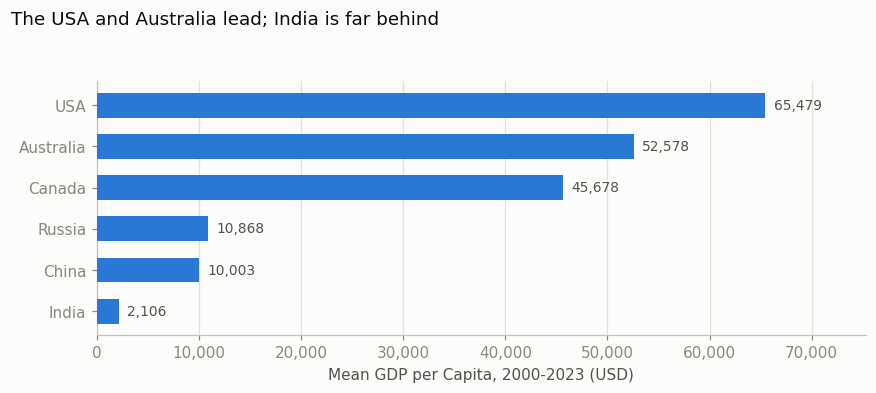

In [36]:
order = bench[TARGET].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order.index, order.values, color=BLUE, height=0.6, zorder=3)
for y, v in enumerate(order.values):
    ax.text(v + 800, y, f"{v:,.0f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, order.max() * 1.15)
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean GDP per Capita, 2000-2023 (USD)")
fig.suptitle("The USA and Australia lead; India is far behind", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### 3.3 GDP per Capita over time

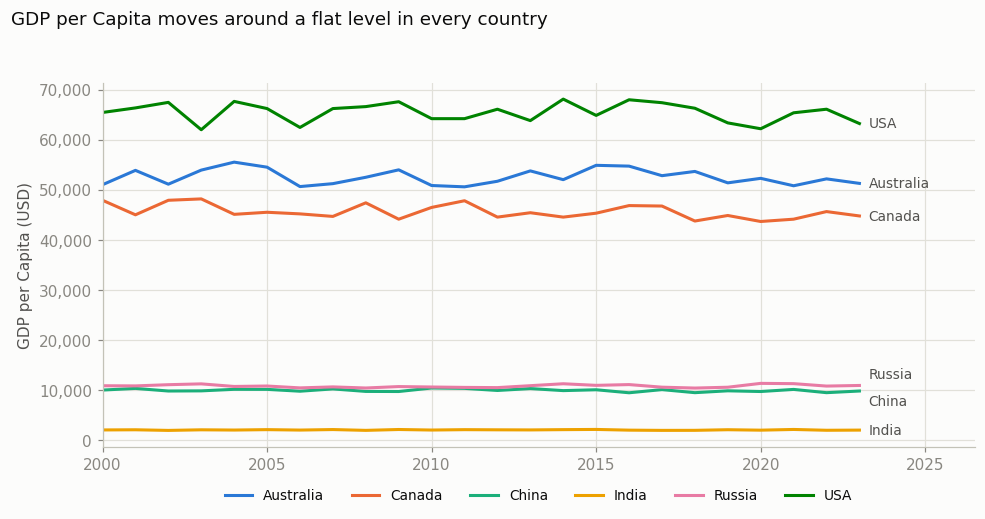

In [37]:
END_NUDGE = {"Russia": 7, "China": -7}  # keeps the two close end labels apart

fig, ax = plt.subplots(figsize=(9, 4.8))
for c in COUNTRIES:
    g = df[df["Country"] == c]
    ax.plot(g["Year"], g[TARGET], color=COUNTRY_COLOR[c], lw=2, label=c)
    ax.annotate(c, (g["Year"].iloc[-1], g[TARGET].iloc[-1]), xytext=(6, END_NUDGE.get(c, 0)),
                textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_xlim(2000, 2026.5)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylabel("GDP per Capita (USD)")
ax.legend(ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=9)
fig.suptitle("GDP per Capita moves around a flat level in every country", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [40]:
# Where each country's name sits relative to its cluster (keeps names off the dots)
LABEL_SIDE = {"Australia": "above", "Canada": "below", "China": "below",
              "India": "right", "Russia": "above", "USA": "above"}


def corr_table(cols, target=TARGET):
    pooled = pd.Series({c: df[c].corr(df[target]) for c in cols})
    dm = df[cols + [target]] - df.groupby("Country")[cols + [target]].transform("mean")
    within = pd.Series({c: dm[c].corr(dm[target]) for c in cols})
    return pd.DataFrame({"Pooled r": pooled, "Within-country r": within}).round(2)


def scatter_panel(ax, xcol, ycol=TARGET):
    ax.scatter(df[xcol], df[ycol], s=34, color=BLUE, alpha=0.6,
               edgecolor=SURFACE, linewidth=0.8, zorder=3)
    for country, g in df.groupby("Country"):
        side = LABEL_SIDE[country]
        if side == "above":
            xy, off, ha, va = (g[xcol].mean(), g[ycol].max()), (0, 5), "center", "bottom"
        elif side == "below":
            xy, off, ha, va = (g[xcol].mean(), g[ycol].min()), (0, -5), "center", "top"
        else:
            xy, off, ha, va = (g[xcol].max(), g[ycol].mean()), (7, 0), "left", "center"
        ax.annotate(country, xy, xytext=off, textcoords="offset points", ha=ha, va=va,
                    fontsize=9, color=INK2, zorder=4)
    ax.yaxis.set_major_formatter(thousands)
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f"Pooled r = {df[xcol].corr(df[ycol]):.2f}", loc="left", fontsize=10, color=INK2)


def objective_view(name, cols, headline):
    display(corr_table(cols))
    fig, axes = plt.subplots(1, len(cols), figsize=(6.2 * len(cols), 4.6), squeeze=False)
    for ax, col in zip(axes[0], cols):
        scatter_panel(ax, col)
    fig.suptitle(headline, x=0.01, ha="left", fontsize=12, color=INK)
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

#### Objective 1: Education and Literacy Impact on GDP per Capita

,Pooled r,Within-country r
Literacy Rate (%),0.56,0.04
Education Expenditure as % of GDP,0.79,0.04


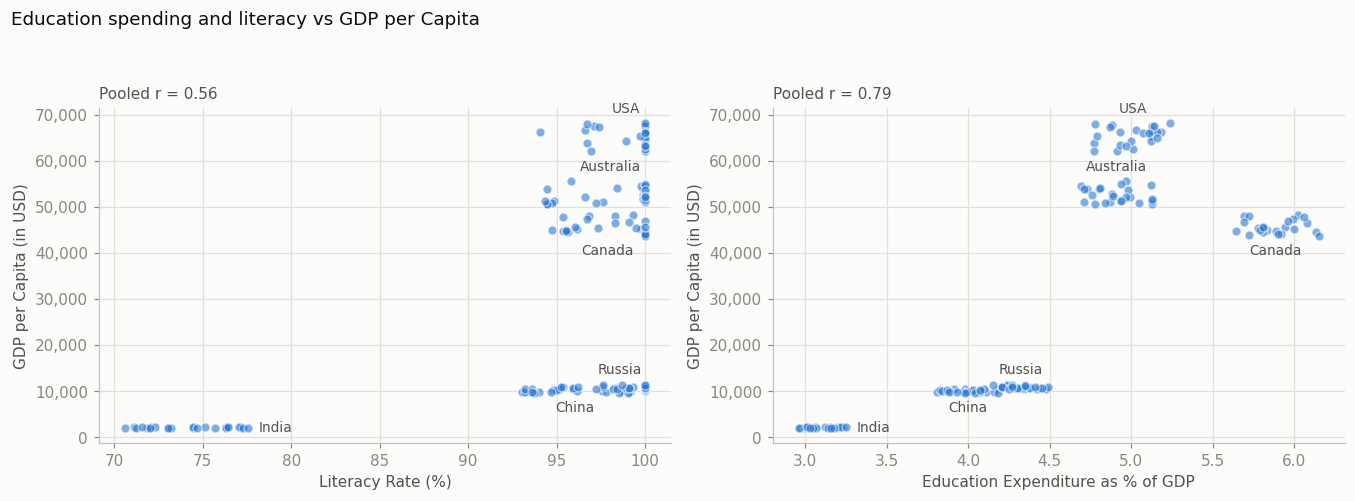

In [41]:
objective_view("Education", OBJECTIVES["1. Education and Literacy"],
               "Education spending and literacy vs GDP per Capita")

**Pooled r** uses all 144 rows together. It captures differences between countries. Education Expenditure at 0.79 means that countries with higher education spending tend to have higher GDP per Capita.

**Within-country r** first removes each country’s own average, then measures the correlation. It captures change over time inside each country. At 0.04 it means that in years when a country spent more on education, its GDP per Capita wasn’t higher.

#### Objective 2: Healthcare Investment and Economic Output

,Pooled r,Within-country r
Healthcare Expenditure per Capita (USD),0.95,0.13
Doctor-to-Patient Ratio,0.40,0.08


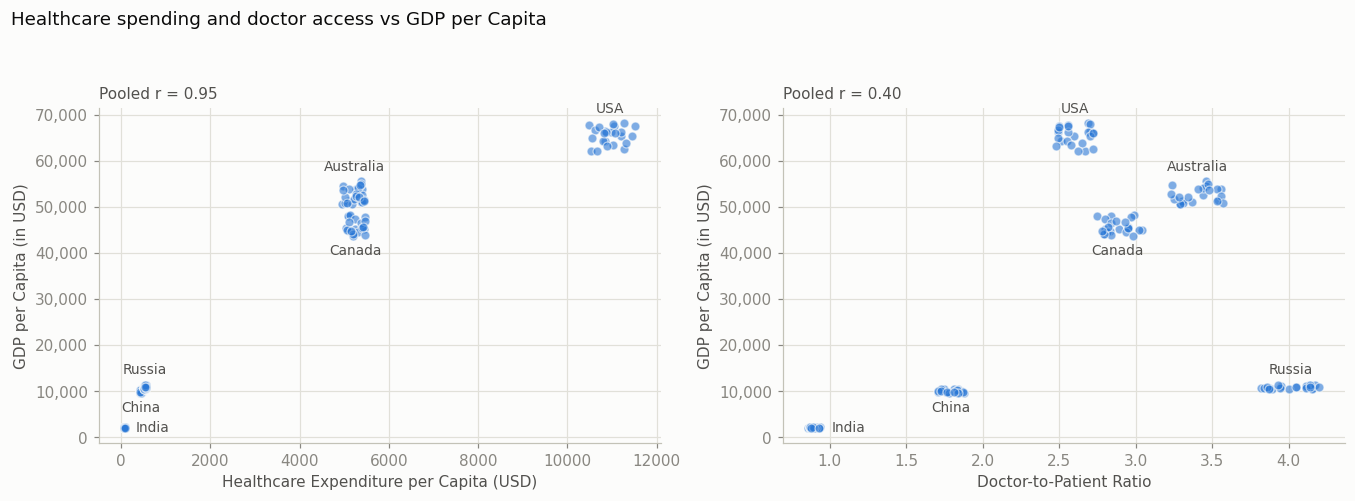

In [43]:
objective_view("Healthcare", OBJECTIVES["2. Healthcare Investment"],
               "Healthcare spending and doctor access vs GDP per Capita")

**Healthcare spending** is very closely tied to GDP per Capita across countries,

So **more doctors per patient** doesn’t go with higher GDP per Capita here.